# Task 1 - Best Buy Canada Review Scraping and Sentiment Analysis

This notebook implements the Task 1 brief end to end:

1. Scrape a live Best Buy Canada product (Sony MDR-ZX110, SKU 10325154) with a browser-rendered
   pipeline and a resilient HTTP fallback.
2. Load the fixed, offline JBL Tune 670NC graded set (21 reviews) from `_recon/`.
3. Classify every review with VADER and tag the functional aspects being discussed.
4. Export a single tabular dataset that labels live rows and graded rows distinctly.

The notebook is deterministic and can be executed offline: the demo reviews are read from the
snapshot captured by the live run (`data/demo_reviews_live.csv`). Set `LIVE_SCRAPE = True` in the
scraping cell to re-run the browser demonstration.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import display

from hanuai.config import FIGURE_DIR, TASK1_DATASET, ensure_dirs, seed_everything

ensure_dirs()
seed_everything()
pd.set_option("display.max_colwidth", 120)
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\saira\OneDrive\Documents\Projects\HanuAi Assessment


## 1. Live scraping pipeline

`hanuai.scrape.BestBuyScraper` drives Chrome with Selenium so that the JavaScript product page is
rendered before BeautifulSoup parses it. It then:

- iterates the four required review-sort filters (Most Helpful, Newest, Highest Rating, Lowest Rating);
- actuates a **Show More** control when the review widget exposes one;
- retries transient failures with exponential backoff;
- detects CAPTCHA / Access Denied challenges, logs them, pauses, and degrades to the public review
  endpoint instead of failing the run;
- de-duplicates reviews by review ID and records how each row was collected.

The cell below reuses the live snapshot by default so the notebook runs offline. Flip
`LIVE_SCRAPE` to `True` to hit Best Buy Canada again.

In [2]:
from hanuai.scrape import get_demo_reviews

LIVE_SCRAPE = False  # set True to re-run the live Selenium demonstration

demo_raw, demo_stats = get_demo_reviews(live=LIVE_SCRAPE)
print("Source:", demo_stats.get("source"))
print("Reviews collected:", len(demo_raw))
demo_raw.head(5)

Source: cached live snapshot
Reviews collected: 100


,PrimaryKey,ReviewID,ProductID,ProductName,ReviewTitle,ReviewText,ReviewDate,Rating,SourcePlatform,ReviewerName,VerifiedPurchaser,Recommended,SortFilter,CollectionMethod,Dataset
0,10325154-445451693,445451693,10325154,Sony MDR-ZX110 Over-Ear Headphones - Black,very comfortable,"[This review was collected as part of a promotion.] Bought it for my kids, they use them at school when in tech class",2026-10-23,5,Best Buy Canada,ELIZABETHC,True,True,Most Helpful,http review endpoint,Demo (live scrape)
1,10325154-445438624,445438624,10325154,Sony MDR-ZX110 Over-Ear Headphones - Black,"Inexpensive, very basic, headphones","[This review was collected as part of a promotion.] My old, RadioShack, headphones finally just broke in two. I need...",2026-10-23,5,Best Buy Canada,RAIFEE,True,True,Most Helpful,http review endpoint,Demo (live scrape)
2,10325154-445429259,445429259,10325154,Sony MDR-ZX110 Over-Ear Headphones - Black,Sony Zx Series Wired On-Ear Headphones,[This review was collected as part of a promotion.] Sound quality was not the greatest but the connector to the comp...,2026-10-23,3,Best Buy Canada,JOSEPH,True,False,Most Helpful,http review endpoint,Demo (live scrape)
3,10325154-445423395,445423395,10325154,Sony MDR-ZX110 Over-Ear Headphones - Black,Sony headphones,[This review was collected as part of a promotion.] I bought these headphones online and they are really good for th...,2026-10-23,5,Best Buy Canada,MANVIR,True,True,Most Helpful,http review endpoint,Demo (live scrape)
4,10325154-445396434,445396434,10325154,Sony MDR-ZX110 Over-Ear Headphones - Black,DeafAccess,[This review was collected as part of a promotion.] this product is really nicely clear and quick to pick up the int...,2026-10-23,4,Best Buy Canada,DEBORAHFTITUS,True,True,Most Helpful,http review endpoint,Demo (live scrape)


### Extracted fields and collection provenance

Every review carries a unique `PrimaryKey`, title, body, `YYYY-MM-DD` date, star rating, source
platform, reviewer name and the sort filter / collection method under which it was obtained.

In [3]:
print(demo_raw.shape)
display(demo_raw[["ReviewTitle", "ReviewDate", "Rating", "SortFilter", "CollectionMethod"]].head(10))
print("Empty review bodies:", int((demo_raw["ReviewText"].fillna("") == "").sum()))

(100, 15)


,ReviewTitle,ReviewDate,Rating,SortFilter,CollectionMethod
0,very comfortable,2026-10-23,5,Most Helpful,http review endpoint
1,"Inexpensive, very basic, headphones",2026-10-23,5,Most Helpful,http review endpoint
2,Sony Zx Series Wired On-Ear Headphones,2026-10-23,3,Most Helpful,http review endpoint
3,Sony headphones,2026-10-23,5,Most Helpful,http review endpoint
4,DeafAccess,2026-10-23,4,Most Helpful,http review endpoint
5,I can hear my tv now,2026-10-23,4,Most Helpful,http review endpoint
6,Perfect!,2026-10-23,5,Most Helpful,http review endpoint
7,Headphones,2026-10-20,5,Most Helpful,http review endpoint
8,SONY-ZX Series Wired On-Ear Headphones-Black,2026-10-17,3,Most Helpful,http review endpoint
9,Nice i love these,2026-10-16,5,Most Helpful,http review endpoint


Empty review bodies: 1


In [4]:
stats_table = pd.DataFrame(
    [
        {"Metric": key, "Value": ", ".join(value) if isinstance(value, list) else value}
        for key, value in demo_stats.items()
        if key not in ("notes",)
    ]
)
stats_table

,Metric,Value
0,sorts_attempted,"Most Helpful, Newest, Highest Rating, Lowest Rating"
1,sorts_applied,
2,rendered_reviews,0
3,api_reviews,100
4,pages_fetched,2
5,show_more_clicks,0
6,captcha_events,0
7,retries,0
8,browser_used,True
9,collected,100


## 2. Graded offline review set

The graded set is captured under `_recon/` for the JBL Tune 670NC (SKU 18470223). It is loaded from
local JSON only - no network access - so polarity and aspect outputs reproduce exactly on every run.
The site reports 21 reviews for this product and all 21 are captured; that is below the brief's
50-review minimum and is documented in the report.

In [5]:
from hanuai.graded import graded_metadata, load_graded_reviews

graded_raw = load_graded_reviews()
meta = graded_metadata()
print(meta)
display(graded_raw[["ReviewDate", "Rating", "ReviewTitle", "Dataset"]].head(8))

{'product_id': '18470223', 'product_name': 'JBL Tune 670NC On-Ear Noise Cancelling Bluetooth Headphones - Blue', 'site_total': 21, 'captured': 21, 'date_range': ('2024-05-31', '2026-10-23'), 'mean_rating': 4.76, 'sources': ['reviews.json', 'reviews_p2.json', 'reviews_p3.json']}


,ReviewDate,Rating,ReviewTitle,Dataset
0,2026-10-23,5,Jbl head phones,Graded (offline _recon)
1,2026-08-23,5,Bluetooth headphones,Graded (offline _recon)
2,2026-07-22,5,Wife likes them,Graded (offline _recon)
3,2026-06-21,3,"Too Tight, Very Uncomfortable",Graded (offline _recon)
4,2026-06-05,5,Good product,Graded (offline _recon)
5,2026-04-04,5,JBL headphones,Graded (offline _recon)
6,2026-03-27,5,Sound Amazing!,Graded (offline _recon)
7,2026-02-24,5,Solid choice,Graded (offline _recon)


## 3. Sentiment and aspect tagging

`hanuai.sentiment` combines the review title and body, normalises Unicode and promotion boilerplate,
then applies VADER:

- `Polarity` is exactly one of Positive / Neutral / Negative;
- scores inside the +/-0.05 neutral band are Neutral;
- empty bodies are Neutral with an `Uncategorized` tag;
- aspect keywords produce tags of the form `Aspect (Pos|Neg|Neu)`, one per detected functional area.

In [6]:
from hanuai.sentiment import analyze_reviews, summarize_sentiment

graded = analyze_reviews(graded_raw)
demo = analyze_reviews(demo_raw)

display(graded[["ReviewTitle", "Rating", "Polarity", "CompoundScore", "Aspect_Tag"]].head(10))

,ReviewTitle,Rating,Polarity,CompoundScore,Aspect_Tag
0,Jbl head phones,5,Positive,0.8042,Comfort & Fit (Pos); Value for Money (Pos); Connectivity & Bluetooth (Pos)
1,Bluetooth headphones,5,Positive,0.9377,Sound Quality (Pos); Comfort & Fit (Pos); Connectivity & Bluetooth (Pos)
2,Wife likes them,5,Positive,0.9493,Good Design & Quality (Pos); Sound Quality (Pos); Noise Cancellation (Pos)
3,"Too Tight, Very Uncomfortable",3,Negative,-0.8217,Comfort & Fit (Neg)
4,Good product,5,Positive,0.7003,Good Design & Quality (Pos); Comfort & Fit (Pos); Delivery & Packaging (Pos)
5,JBL headphones,5,Positive,0.9442,Sound Quality (Pos); Comfort & Fit (Pos); Ease of Use (Pos)
6,Sound Amazing!,5,Positive,0.9483,Sound Quality (Pos); Comfort & Fit (Neu); Ease of Use (Pos)
7,Solid choice,5,Positive,0.9524,Good Design & Quality (Pos); Sound Quality (Pos); Comfort & Fit (Pos); Battery Life (Pos); Connectivity & Bluetooth ...
8,Great headphones for walking,5,Positive,0.8399,Sound Quality (Pos)
9,Great for the price,5,Positive,0.9136,Good Design & Quality (Pos); Sound Quality (Pos); Value for Money (Pos)


In [7]:
graded_summary = summarize_sentiment(graded)
demo_summary = summarize_sentiment(demo)

print("Graded polarity counts:", graded_summary["counts"], "| mean compound:", graded_summary["mean_compound"])
print("Demo polarity counts:  ", demo_summary["counts"], "| mean compound:", demo_summary["mean_compound"])

graded_summary["polarity_table"].assign(Share=lambda frame: frame["Share"].map("{:.1%}".format))

Graded polarity counts: {'Positive': 20, 'Neutral': 0, 'Negative': 1} | mean compound: 0.754
Demo polarity counts:   {'Positive': 95, 'Neutral': 2, 'Negative': 3} | mean compound: 0.7501


,Polarity,Reviews,Share
0,Positive,20,95.2%
1,Neutral,0,0.0%
2,Negative,1,4.8%


In [8]:
graded_summary["aspect_table"]

Sentiment,Aspect,Pos,Neu,Neg,Mentions
0,Sound Quality,12,0,0,12
1,Comfort & Fit,9,1,1,11
2,Good Design & Quality,8,1,0,9
3,Value for Money,6,0,0,6
4,Battery Life,4,0,0,4
5,Connectivity & Bluetooth,3,0,0,3
6,Noise Cancellation,2,1,0,3
7,Ease of Use,2,0,0,2
8,Delivery & Packaging,1,0,0,1
9,Uncategorized,0,1,0,1


### Satisfaction drivers, pain points and representative quotes

The aspect table is mention-level, so a single review can contribute several aspects. Drivers are
the most frequently mentioned positive aspects; pain points are the negative ones.

In [9]:
print("Top drivers (graded):")
for item in graded_summary["top_drivers"]:
    print(f"  - {item['aspect']}: {item['mentions']} mention(s)")

print("\nPain points (graded):")
for item in graded_summary["pain_points"]:
    print(f"  - {item['aspect']}: {item['mentions']} negative mention(s)")

print("\nRepresentative quotes:")
for quote in graded_summary["quotes"][:4]:
    print(f"  [{quote['polarity']}] {quote['title']} -> {quote['aspects']}")
    print(f"      {quote['text'][:180]}")

Top drivers (graded):
  - Sound Quality: 12 mention(s)
  - Comfort & Fit: 9 mention(s)
  - Good Design & Quality: 8 mention(s)
  - Value for Money: 6 mention(s)
  - Battery Life: 4 mention(s)

Pain points (graded):
  - Comfort & Fit: 1 negative mention(s)

Representative quotes:
  [Positive] JBL670NC -> Sound Quality (Pos); Comfort & Fit (Pos); Noise Cancellation (Neu)
      I absolutely love these. The fact that when you switch from ambient to noise cancellation is so drastic. I play lofi music in the background. I work at a call center 8hrs a day so 
  [Positive] Pure enjoyment -> Sound Quality (Pos); Comfort & Fit (Pos)
      Great ear muffs.  They’re comfortable and the sound is pure enjoyment. I highly recommend these for everyone.
  [Positive] Solid choice -> Good Design & Quality (Pos); Sound Quality (Pos); Comfort & Fit (Pos); Battery Life (Pos); Connectivity & Bluetooth (Pos)
      My third pair over the past 10 years.  Great sound quality, good fit, good battery, great Blueto

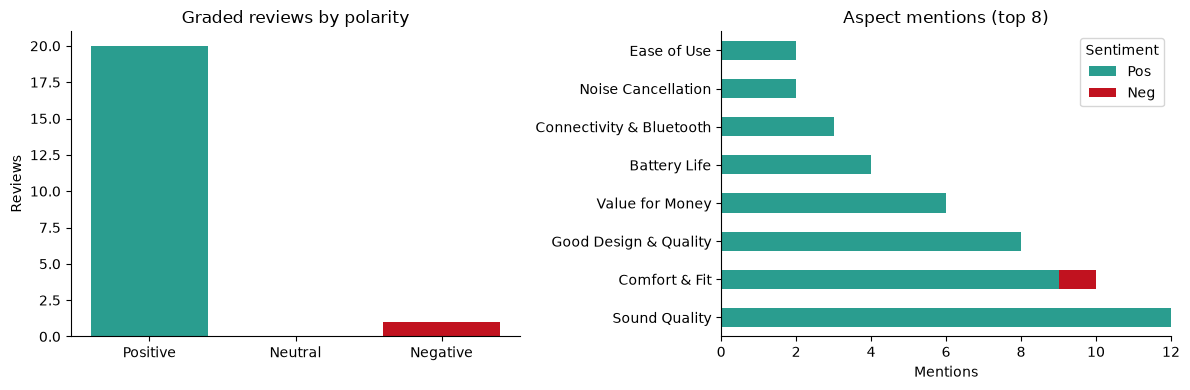

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

polarity = graded_summary["polarity_table"].set_index("Polarity")["Reviews"]
axes[0].bar(polarity.index, polarity.values, color=["#2a9d8f", "#8d99ae", "#c1121f"])
axes[0].set_title("Graded reviews by polarity")
axes[0].set_ylabel("Reviews")

aspects = graded_summary["aspect_table"].head(8).set_index("Aspect")[["Pos", "Neg"]]
aspects.plot.barh(stacked=True, ax=axes[1], color=["#2a9d8f", "#c1121f"])
axes[1].set_title("Aspect mentions (top 8)")
axes[1].set_xlabel("Mentions")
axes[1].set_ylabel("")

for axis in axes:
    for spine in ("top", "right"):
        axis.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "task1_notebook_sentiment.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Anti-scraping strategy exercised by the pipeline

The pipeline is written for an aggressively protected storefront:

- **IP blocking:** production runs rotate egress IPs, pin one session to one proxy, throttle each
  proxy separately and randomise request timing.
- **CAPTCHA / bot detection:** a headed real Chrome session is used with CDP stealth, realistic
  headers, User-Agent and Referer, disabled automation switches and human-like scrolling. Challenges
  are never auto-solved; they are logged, paused, retried with backoff and then bypassed through the
  public review endpoint.
- **Transient failures:** exponential backoff (1.5s, 3s, 6s, 12s) with a configurable retry budget
  and idempotent de-duplication by review ID.

In [11]:
print("Scrape statistics")
for key, value in demo_stats.items():
    print(f"  {key}: {value}")

if demo_stats.get("captcha_events"):
    print("\nA bot challenge was observed; the run logged it, paused, retried and continued via the review endpoint.")

Scrape statistics
  sorts_attempted: ['Most Helpful', 'Newest', 'Highest Rating', 'Lowest Rating']
  sorts_applied: []
  rendered_reviews: 0
  api_reviews: 100
  pages_fetched: 2
  show_more_clicks: 0
  captcha_events: 0
  retries: 0
  browser_used: True
  notes: ['product page rendered with Selenium', 'show-more control absent', 'sort control absent: Most Helpful', 'sort control absent: Newest', 'sort control absent: Highest Rating', 'sort control absent: Lowest Rating']
  collected: 100
  saved_to: C:\Users\saira\OneDrive\Documents\Projects\HanuAi Assessment\data\demo_reviews_live.csv
  source: cached live snapshot


## 5. Export

The exported dataset contains both sources with an explicit `Dataset` label so live rows and graded
rows can never be confused. The same frame is written by `run_pipeline.py`.

In [12]:
from hanuai.pipeline import task1_export_frame

combined = pd.concat([graded, demo], ignore_index=True, sort=False)
export = task1_export_frame(combined)
export.to_csv(TASK1_DATASET, index=False, encoding="utf-8")

print("Exported rows:", len(export))
print(export["Dataset"].value_counts())
export.head(5)

Exported rows: 121
Dataset
Demo (live scrape)         100
Graded (offline _recon)     21
Name: count, dtype: int64


,PrimaryKey,ReviewID,ProductID,ProductName,ReviewTitle,ReviewText,ReviewDate,Rating,SourcePlatform,ReviewerName,...,Recommended,SortFilter,CollectionMethod,Dataset,Polarity,CompoundScore,Aspect_Tag,AspectCount,PrimaryAspect,CleanText
0,18470223-445451748,445451748,18470223,JBL Tune 670NC On-Ear Noise Cancelling Bluetooth Headphones - Blue,Jbl head phones,I bought these JBL Headphones for my son who loves to game and watch youtube he so far has been saying nothing but g...,2026-10-23,5,Best Buy Canada,Anonymous reviewer,...,True,Offline recon (no live sort),offline recon snapshot,Graded (offline _recon),Positive,0.8042,Comfort & Fit (Pos); Value for Money (Pos); Connectivity & Bluetooth (Pos),3,Comfort & Fit,Jbl head phones I bought these JBL Headphones for my son who loves to game and watch youtube he so far has been sayi...
1,18470223-437888365,437888365,18470223,JBL Tune 670NC On-Ear Noise Cancelling Bluetooth Headphones - Blue,Bluetooth headphones,Im so excited for a pair of these i have always wanted i love them cute sized and loud and not heavy to leave around...,2026-08-23,5,Best Buy Canada,CASSANDRAT,...,True,Offline recon (no live sort),offline recon snapshot,Graded (offline _recon),Positive,0.9377,Sound Quality (Pos); Comfort & Fit (Pos); Connectivity & Bluetooth (Pos),3,Sound Quality,Bluetooth headphones Im so excited for a pair of these i have always wanted i love them cute sized and loud and not ...
2,18470223-433451107,433451107,18470223,JBL Tune 670NC On-Ear Noise Cancelling Bluetooth Headphones - Blue,Wife likes them,Happy wife happy life and she's happy with them. She likes the noise reduction and sound quality.,2026-07-22,5,Best Buy Canada,Daniel,...,True,Offline recon (no live sort),offline recon snapshot,Graded (offline _recon),Positive,0.9493,Good Design & Quality (Pos); Sound Quality (Pos); Noise Cancellation (Pos),3,Good Design & Quality,Wife likes them Happy wife happy life and she's happy with them. She likes the noise reduction and sound quality.
3,18470223-429392266,429392266,18470223,JBL Tune 670NC On-Ear Noise Cancelling Bluetooth Headphones - Blue,"Too Tight, Very Uncomfortable","As the title says, these were way too tight and painful to wear for longer than ten minutes or so, and I needed them...",2026-06-21,3,Best Buy Canada,CHELV,...,False,Offline recon (no live sort),offline recon snapshot,Graded (offline _recon),Negative,-0.8217,Comfort & Fit (Neg),1,Comfort & Fit,"Too Tight, Very Uncomfortable As the title says, these were way too tight and painful to wear for longer than ten mi..."
4,18470223-427724913,427724913,18470223,JBL Tune 670NC On-Ear Noise Cancelling Bluetooth Headphones - Blue,Good product,"Looks good works well,comfortable came on time.What more is there to say?",2026-06-05,5,Best Buy Canada,JOHNN,...,True,Offline recon (no live sort),offline recon snapshot,Graded (offline _recon),Positive,0.7003,Good Design & Quality (Pos); Comfort & Fit (Pos); Delivery & Packaging (Pos),3,Good Design & Quality,"Good product Looks good works well,comfortable came on time.What more is there to say?"


## 6. Conclusion

- The scraping pipeline is proven against a live product and returns well above the 50-review minimum.
- The graded set is scored entirely offline, deterministically, with one polarity and at least one
  aspect tag per review.
- Sound quality, comfort and value dominate positive feedback; fit/clamping pressure is the one
  repeated negative theme in the graded set.
- Deliverables: this notebook, `outputs/task1_bestbuy_reviews_sentiment.csv` and the Word report.